# 02 — Phát hiện bất thường

Isolation Forest và One-Class SVM được fit trên **tập train, không dùng nhãn**. Nhãn validation chỉ dùng để chọn cấu hình One-Class SVM và chọn ngưỡng. **Tập test không được dùng trong notebook này**; đánh giá cuối cùng nằm ở notebook 04 sau khi đã khóa cấu hình.

Quy ước: `human = 0`, `bot = 1`; điểm bất thường là `-decision_function`, điểm càng lớn càng bất thường (được coi là giống bot).

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise RuntimeError("Mở notebook từ thư mục gốc dự án hoặc notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, RANDOM_STATE
print("Project root:", project_root)


Project root: D:\Son_Work_Space\Data_Mining\Social-Media-Bot-Fake-Account-Detection


In [2]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score, roc_auc_score

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR
from src.evaluate import evaluate_predictions
from src.data import SPLIT_NAMES, load_profiles, split_features
from src.features import build_features
from src.train import (
    anomaly_scores, predict_bot, select_threshold,
    train_isolation_forest, train_one_class_svm,
)

profiles, _ = load_profiles()
features = build_features(profiles)
train, validation, test = split_features(features)

X_train = train[list(FEATURE_COLUMNS)]
X_val, y_val = validation[list(FEATURE_COLUMNS)], validation["label"].to_numpy()
display(pd.DataFrame({
    name: {"rows": len(part), "bot_share": part["label"].mean()}
    for name, part in zip(SPLIT_NAMES, (train, validation, test))
}).T)

,rows,bot_share
train,22462.0,0.331894
validation,7488.0,0.331864
test,7488.0,0.331864


## Mốc so sánh trên validation

Hai mốc tối thiểu mà một detector cần vượt qua:

- **Xếp hạng ngẫu nhiên:** ROC-AUC = 0,5 và AP = tỷ lệ bot.
- **Gắn nhãn tất cả là bot:** recall = 1, precision = tỷ lệ bot; F1 lớp bot = 2p / (1 + p).

In [3]:
def validation_metrics(y_pred, scores):
    """Shared evaluate_predictions() on validation, plus the share flagged as bot."""
    return {**evaluate_predictions(y_val, y_pred, scores), "flagged_share": float(np.mean(y_pred))}


bot_share = y_val.mean()
baselines = pd.DataFrame([
    {"model": "random ranking", "threshold": "-", "ap": bot_share, "roc_auc": 0.5},
    {"model": "all bot", "threshold": "-", **validation_metrics(np.ones_like(y_val), np.zeros(len(y_val)))},
])
baselines.loc[1, ["ap", "roc_auc"]] = [bot_share, 0.5]
display(baselines.round(3))

,model,threshold,ap,roc_auc,precision_bot,recall_bot,f1_bot,macro_f1,accuracy,tn,fp,fn,tp,flagged_share
0,random ranking,-,0.332,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,all bot,-,0.332,0.5,0.332,1.0,0.498,0.249,0.332,0.0,5003.0,0.0,2485.0,1.0


## Chọn cấu hình One-Class SVM trên validation

Thứ hạng điểm của One-Class SVM phụ thuộc vào `nu` và `gamma`, nên thử một lưới nhỏ và chọn theo **AP trên validation** (không phụ thuộc ngưỡng). Isolation Forest giữ cấu hình mặc định của `train_isolation_forest` (300 cây, `contamination="auto"`); `contamination` chỉ dời ngưỡng mặc định, không đổi thứ hạng điểm.

In [4]:
search = []
for nu in (0.05, 0.1, 0.2):
    for gamma in ("scale", 0.05, 1.0):
        start = time.perf_counter()
        candidate = train_one_class_svm(X_train, nu=nu, gamma=gamma)
        seconds = time.perf_counter() - start
        scores = anomaly_scores(candidate, X_val)
        search.append({
            "nu": nu, "gamma": gamma, "fit_seconds": seconds,
            "ap": average_precision_score(y_val, scores),
            "roc_auc": roc_auc_score(y_val, scores),
        })
search = pd.DataFrame(search).sort_values("ap", ascending=False, ignore_index=True)
display(search.round(3))
best_ocsvm = {"nu": float(search.loc[0, "nu"]), "gamma": search.loc[0, "gamma"]}
print("Cấu hình One-Class SVM được chọn:", best_ocsvm)

,nu,gamma,fit_seconds,ap,roc_auc
0,0.05,0.05,0.813,0.372,0.565
1,0.05,1.0,0.852,0.368,0.550
2,0.10,0.05,2.043,0.362,0.552
3,0.10,1.0,2.092,0.356,0.527
4,0.20,0.05,4.754,0.354,0.538
5,0.10,scale,1.826,0.347,0.524
6,0.05,scale,0.866,0.347,0.524
7,0.20,scale,3.928,0.345,0.520
8,0.20,1.0,3.922,0.344,0.502


Cấu hình One-Class SVM được chọn: {'nu': 0.05, 'gamma': 0.05}


## Fit cấu hình cuối trên train

Chỉ `X_train` được truyền vào `fit`; pipeline mang theo imputer (và `log1p` + scaler cho One-Class SVM), nên tiền xử lý chỉ học từ train.

In [5]:
trainers = {"isolation_forest": train_isolation_forest, "one_class_svm": train_one_class_svm}
configs = {"isolation_forest": {"n_estimators": 300, "contamination": "auto"}, "one_class_svm": best_ocsvm}
models, fit_seconds, val_scores = {}, {}, {}
for name, train_model in trainers.items():
    start = time.perf_counter()
    models[name] = train_model(X_train, **configs[name])
    fit_seconds[name] = time.perf_counter() - start
    val_scores[name] = anomaly_scores(models[name], X_val)
pd.Series(fit_seconds, name="fit_seconds").round(2)

isolation_forest    0.49
one_class_svm       0.96
Name: fit_seconds, dtype: float64

## Ngưỡng mặc định và ngưỡng chọn trên validation

- **Mặc định:** dùng `predict()` của detector (`-1` → bot). Đây là thiết lập hoàn toàn không giám sát.
- **Validation F1:** `select_threshold()` chọn ngưỡng điểm cho F1 lớp bot cao nhất trên nhãn validation. Thiết lập này **có dùng nhãn**, nên không còn là phát hiện bất thường thuần túy.

In [6]:
rows, thresholds = [], {}
for name, model in models.items():
    scores = val_scores[name]
    thresholds[name] = select_threshold(y_val, scores)
    rows.append({"model": name, "threshold": "default",
                 **validation_metrics(predict_bot(model, X_val), scores)})
    rows.append({"model": name, "threshold": f"validation F1 ({thresholds[name]['threshold']:.4g})",
                 **validation_metrics(predict_bot(model, X_val, thresholds[name]["threshold"]), scores)})
results = pd.DataFrame(rows)
display(pd.concat([results, baselines], ignore_index=True).round(3))

,model,threshold,precision_bot,recall_bot,f1_bot,macro_f1,ap,roc_auc,accuracy,tn,fp,fn,tp,flagged_share
0,isolation_forest,default,0.319,0.100,0.152,0.458,0.288,0.378,0.631,4474.0,529.0,2237.0,248.0,0.104
1,isolation_forest,validation F1 (-0.1277),0.332,1.000,0.498,0.249,0.288,0.378,0.332,1.0,5002.0,0.0,2485.0,1.000
2,one_class_svm,default,0.329,0.050,0.087,0.436,0.372,0.565,0.651,4748.0,255.0,2360.0,125.0,0.051
3,one_class_svm,validation F1 (-97.56),0.351,0.876,0.501,0.407,0.372,0.565,0.422,984.0,4019.0,309.0,2176.0,0.827
4,random ranking,-,NaN,NaN,NaN,NaN,0.332,0.500,NaN,NaN,NaN,NaN,NaN,NaN
5,all bot,-,0.332,1.000,0.498,0.249,0.332,0.500,0.332,0.0,5003.0,0.0,2485.0,1.000


## Phân phối điểm bất thường theo nhãn

Nếu bot là điểm bất thường, phân phối điểm của bot phải lệch sang phải so với người thật.

Đã lưu: reports/figures/anomaly_score_distribution_validation.png


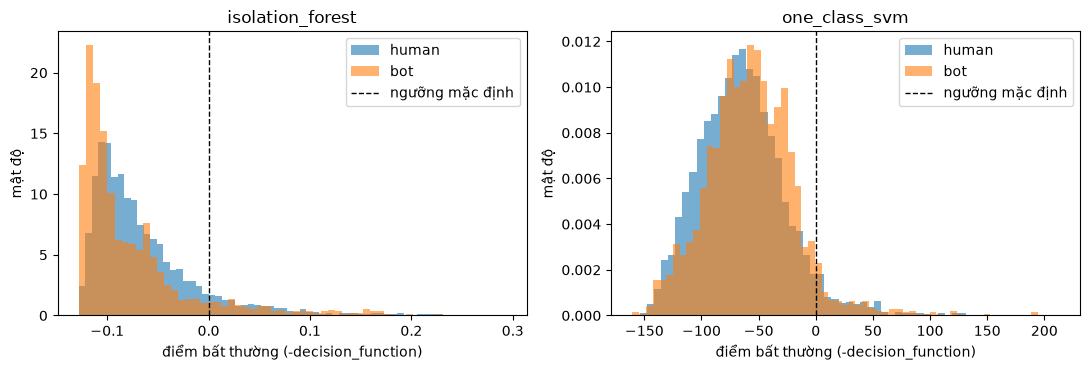

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, scores) in zip(axes, val_scores.items()):
    for label, title in ((0, "human"), (1, "bot")):
        ax.hist(scores[y_val == label], bins=60, alpha=0.6, density=True, label=title)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="ngưỡng mặc định")
    ax.set(title=name, xlabel="điểm bất thường (-decision_function)", ylabel="mật độ")
    ax.legend()
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_path = FIGURES_DIR / "anomaly_score_distribution_validation.png"
fig.savefig(figure_path, dpi=150)
print("Đã lưu:", figure_path.relative_to(project_root).as_posix())
plt.show()

## Tài khoản nào bị gắn cờ?

So sánh trung vị đặc trưng giữa tài khoản bị gắn cờ (ngưỡng mặc định) và không bị gắn cờ trên validation, cùng tỷ lệ bot thực tế trong mỗi nhóm.

In [8]:
profile_rows = []
for name, model in models.items():
    flagged = predict_bot(model, X_val)
    for value, group in ((1, "flagged"), (0, "not flagged")):
        part = validation[flagged == value]
        profile_rows.append({
            "model": name, "group": group, "rows": len(part), "bot_share": part["label"].mean(),
            **part[list(FEATURE_COLUMNS)].median().to_dict(),
        })
display(pd.DataFrame(profile_rows).round(2))

bot_medians = validation.groupby("label")[list(FEATURE_COLUMNS)].median().rename(index={0: "human", 1: "bot"})
display(bot_medians.round(2))

,model,group,rows,bot_share,follower_following_ratio,posting_frequency,account_age_days,bio_length
0,isolation_forest,flagged,777,0.32,54.00,19.88,2911.0,98.0
1,isolation_forest,not flagged,6711,0.33,1.27,1.31,3229.0,54.0
2,one_class_svm,flagged,380,0.33,1.88,0.95,3123.5,61.0
3,one_class_svm,not flagged,7108,0.33,1.44,1.53,3214.0,57.0


,follower_following_ratio,posting_frequency,account_age_days,bio_length
label,,,,
human,1.69,2.48,3399.0,73.0
bot,1.01,0.84,2875.0,35.0


## Lưu model

Mỗi file trong `models/` chứa pipeline đã fit, danh sách đặc trưng, cấu hình, hai ngưỡng và kết quả validation. `models/` bị Git bỏ qua; chạy lại notebook này để tạo lại file. Bảng kết quả validation được lưu vào `reports/anomaly_validation_metrics.csv`.

In [9]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
for name, model in models.items():
    bundle = {
        "model": model,
        "feature_columns": list(FEATURE_COLUMNS),
        "config": configs[name],
        "random_state": RANDOM_STATE,
        # None means the detector's own predict(): -1 -> bot.
        "thresholds": {"default": None, "validation_f1": thresholds[name]["threshold"]},
        "validation_metrics": results.loc[results["model"] == name].to_dict("records"),
        "fit_seconds": fit_seconds[name],
        "sklearn_version": sklearn.__version__,
    }
    joblib.dump(bundle, MODELS_DIR / f"{name}.joblib")
    print("Đã lưu:", (MODELS_DIR / f"{name}.joblib").relative_to(project_root).as_posix())

results.to_csv(REPORTS_DIR / "anomaly_validation_metrics.csv", index=False)
print("Đã lưu:", (REPORTS_DIR / "anomaly_validation_metrics.csv").relative_to(project_root).as_posix())

Đã lưu: models/isolation_forest.joblib
Đã lưu: models/one_class_svm.joblib
Đã lưu: reports/anomaly_validation_metrics.csv


## Kết luận trên validation

Số liệu dưới đây lấy từ lần chạy đã lưu trong notebook (seed 42, split dùng chung). Cấu hình One-Class SVM và ngưỡng đều được chọn trên **cùng** tập validation, nên các số "validation F1" có thể lạc quan; con số khách quan sẽ là kết quả test ở notebook 04.

- **Isolation Forest không phát hiện được bot:** ROC-AUC 0,378 và AP 0,288, đều thấp hơn mốc xếp hạng ngẫu nhiên (0,5 và 0,332). Các tài khoản bị gắn cờ có tỷ lệ follower/following trung vị 54, đăng 19,9 bài/ngày và bio dài 98 ký tự, giống tài khoản nổi tiếng/truyền thông hơn là bot; tỷ lệ bot trong nhóm này (0,32) không cao hơn tỷ lệ chung (0,33).
- **One-Class SVM chỉ nhỉnh hơn ngẫu nhiên một chút:** cấu hình tốt nhất (`nu=0.05`, `gamma=0.05`) đạt ROC-AUC 0,565 và AP 0,372.
- **Ngưỡng mặc định gắn cờ quá ít:** F1 lớp bot 0,152 (Isolation Forest) và 0,087 (One-Class SVM).
- **Ngưỡng chọn trên validation không thực sự cứu được:** Isolation Forest suy biến thành "tất cả là bot" (F1 0,498); One-Class SVM gắn cờ 82,7% tài khoản và đạt F1 0,501, gần như bằng mốc "tất cả là bot".

**Giải thích:** trong dữ liệu này bot chiếm 33% và có hồ sơ khá "điển hình" (trung vị tỷ lệ follower/following 1,01, bio 35 ký tự), nên chúng nằm trong vùng dày đặc của không gian đặc trưng chứ không phải điểm ngoại lai. Điểm ngoại lai thực sự chủ yếu là tài khoản người thật có lượng follower rất lớn. Vì vậy, với bốn đặc trưng hồ sơ này, giả định "bot = bất thường" không đứng vững; mô hình có giám sát (notebook 03) là mốc cần so sánh.

Không đảo dấu điểm số dù Isolation Forest có ROC-AUC dưới 0,5: chọn hướng điểm bằng nhãn sẽ biến detector thành mô hình có giám sát.